In [8]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
from pathlib import Path

In [9]:
path = "/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/output/run_2025-12-30_11-34-08"
path = Path(path) / 'logs'

# Metrics (Overall)


In [10]:
test_data = pd.read_csv(path / 'test_metrics_per_graph.csv')
train_data = pd.read_csv(path / 'train_metrics_per_graph.csv')
print(test_data.head())


   epoch  dataset_name        loss           mse           mae          rmse  \
0      1     wn18rr_v4   26.814016  2.599390e+17  1.515602e+08  5.098421e+08   
1      1          swdf   18.641250  1.976535e+10  6.661364e+04  1.405893e+05   
2      1      wikidata  119.906031  2.782467e+59  5.140187e+28  5.274910e+29   
3      1          lubm   32.691986  2.283674e+12  4.328256e+05  1.511183e+06   
4      1  fb237_v4_ind   25.541405  5.524130e+15  2.366652e+07  7.432449e+07   

        q_error  
0  4.043529e+03  
1  6.519140e+02  
2  1.514083e+28  
3  3.025845e+05  
4  1.803826e+03  


# Metric Visualizations

Separate plots for each metric, showing test and train data in different figures.

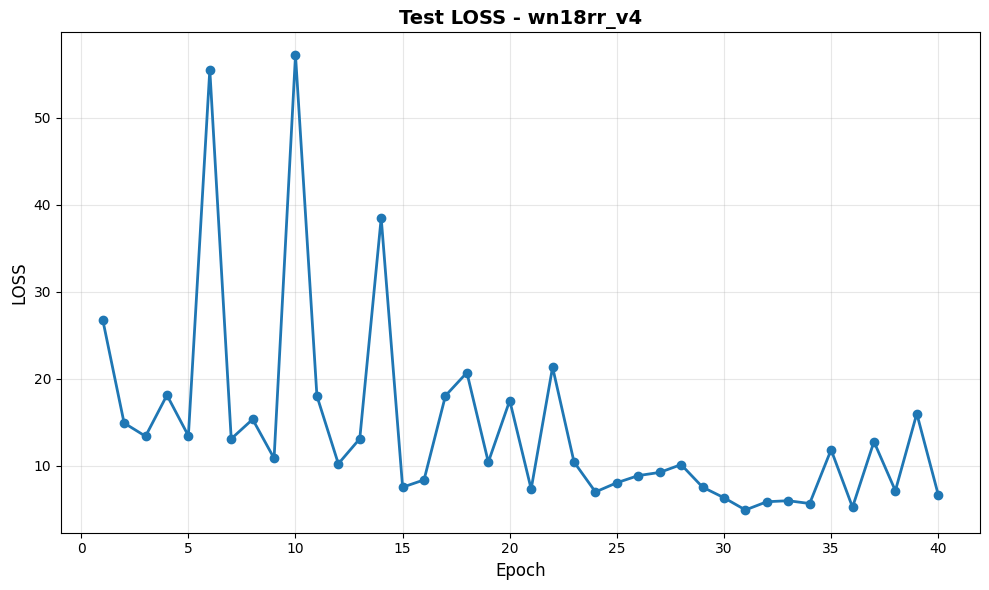

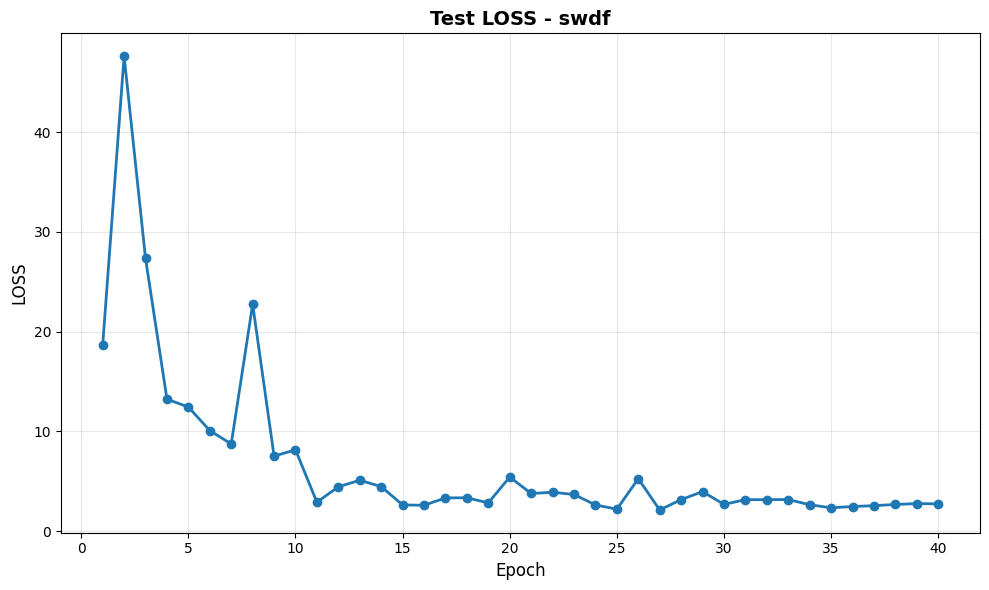

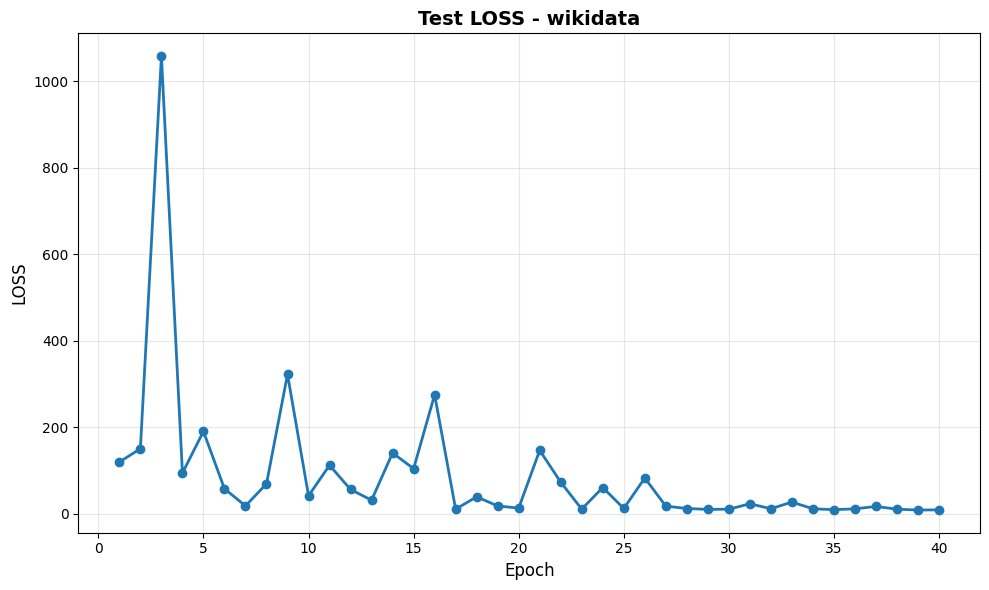

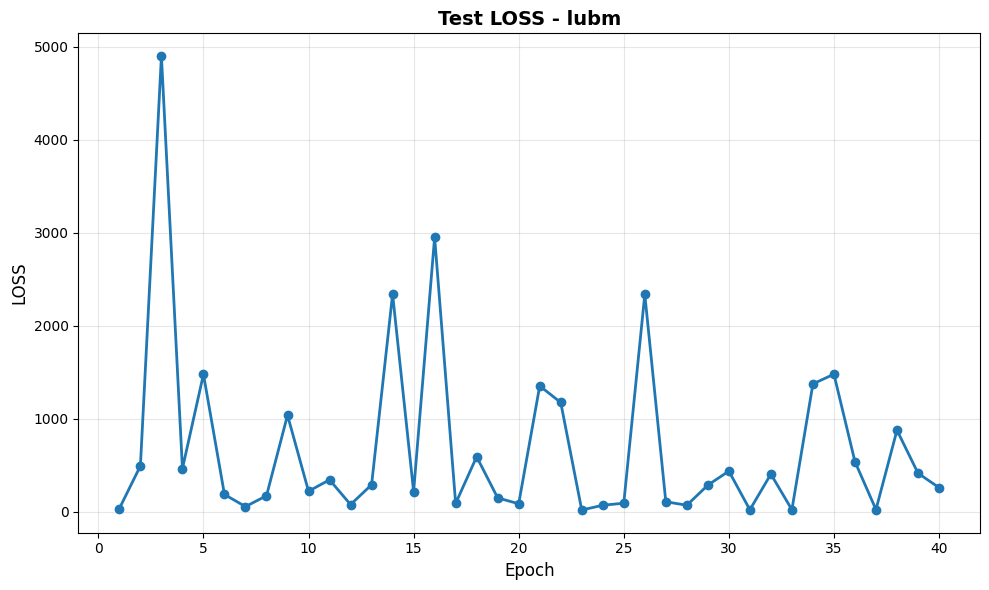

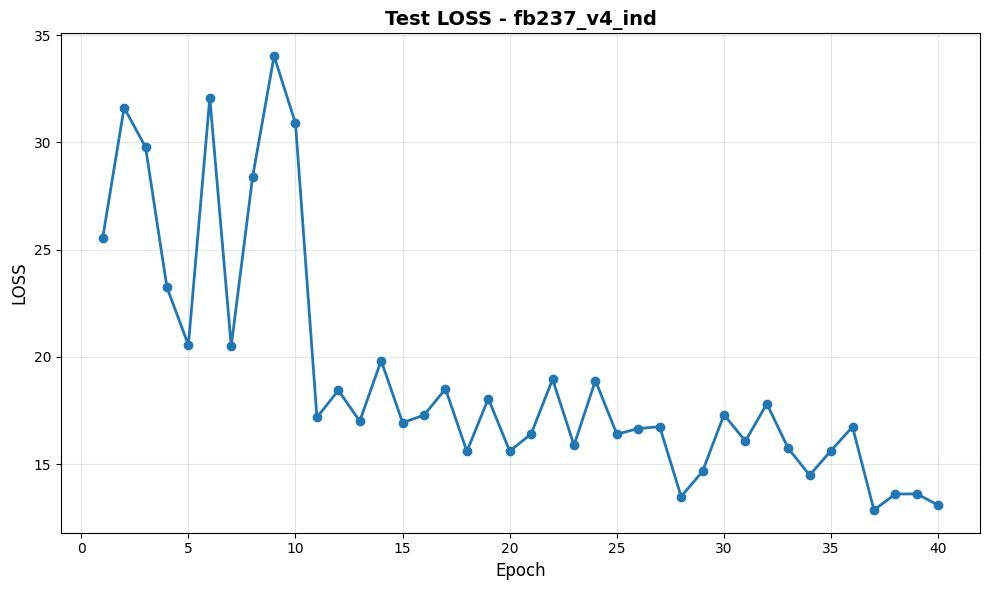

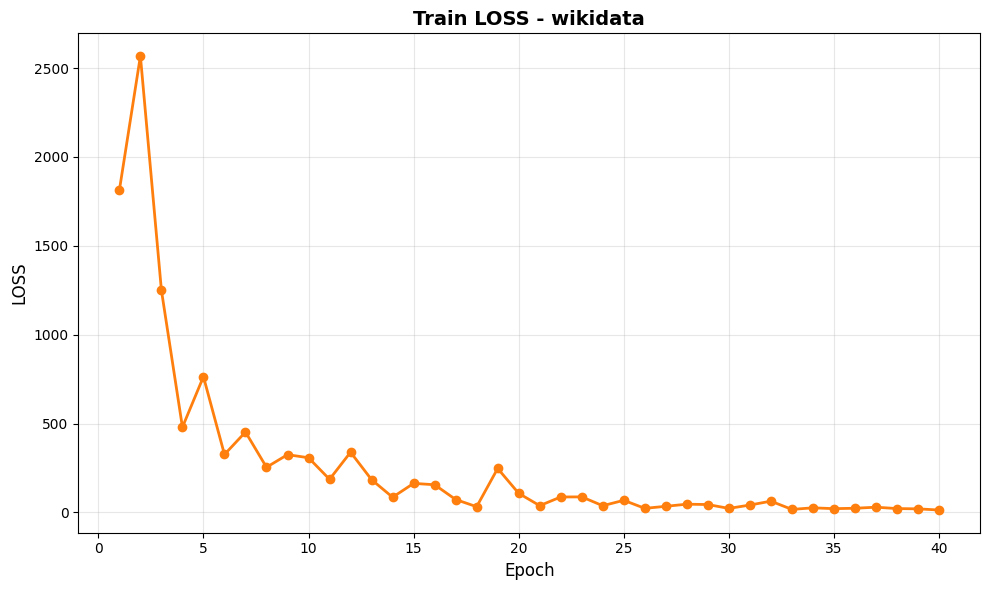

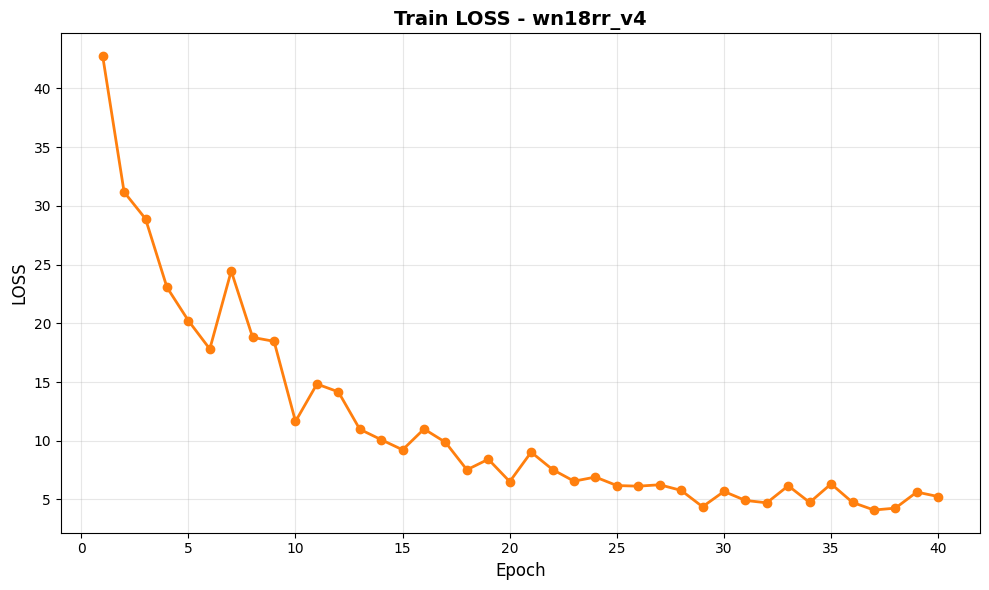

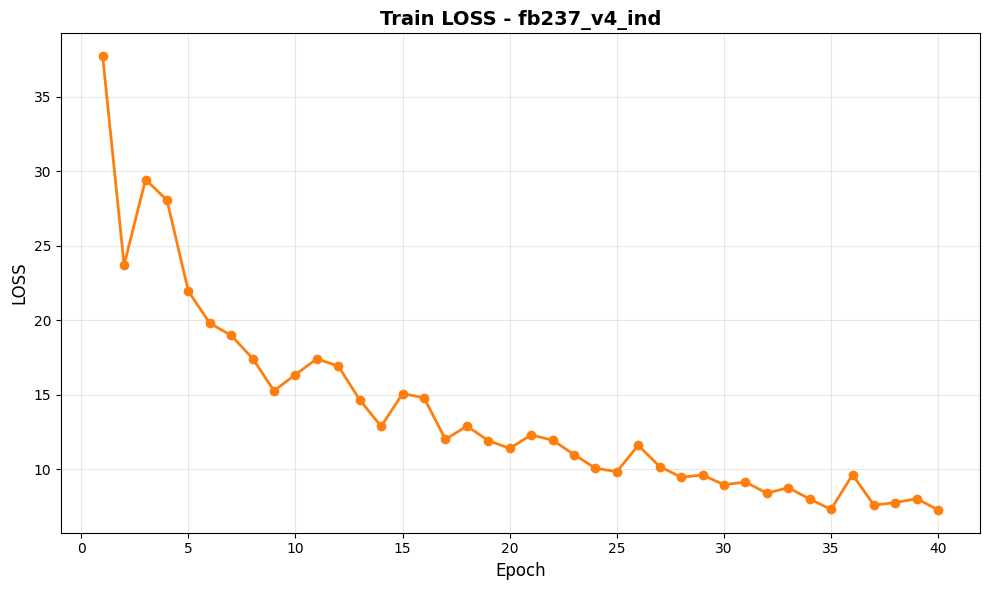

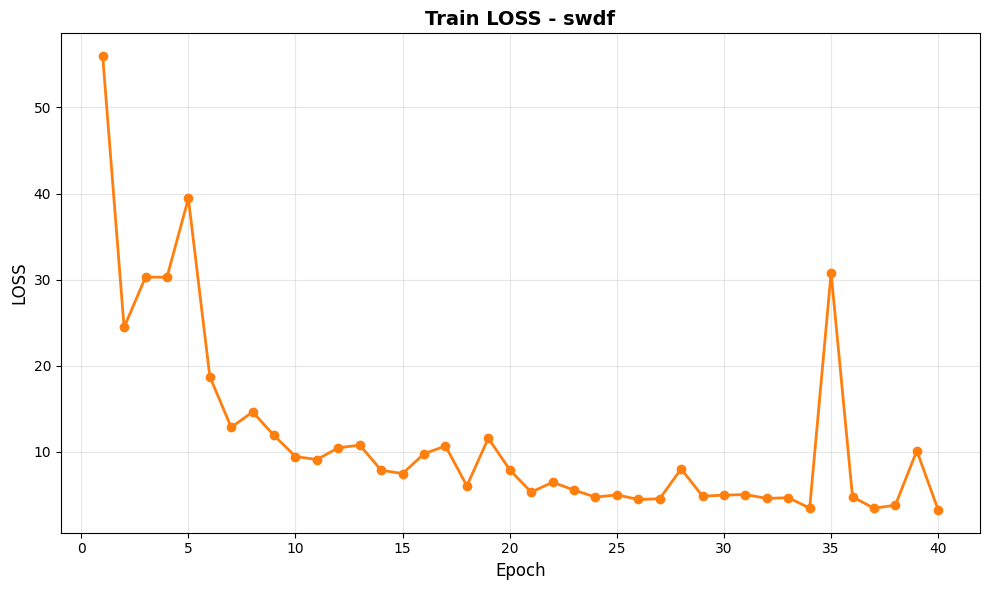

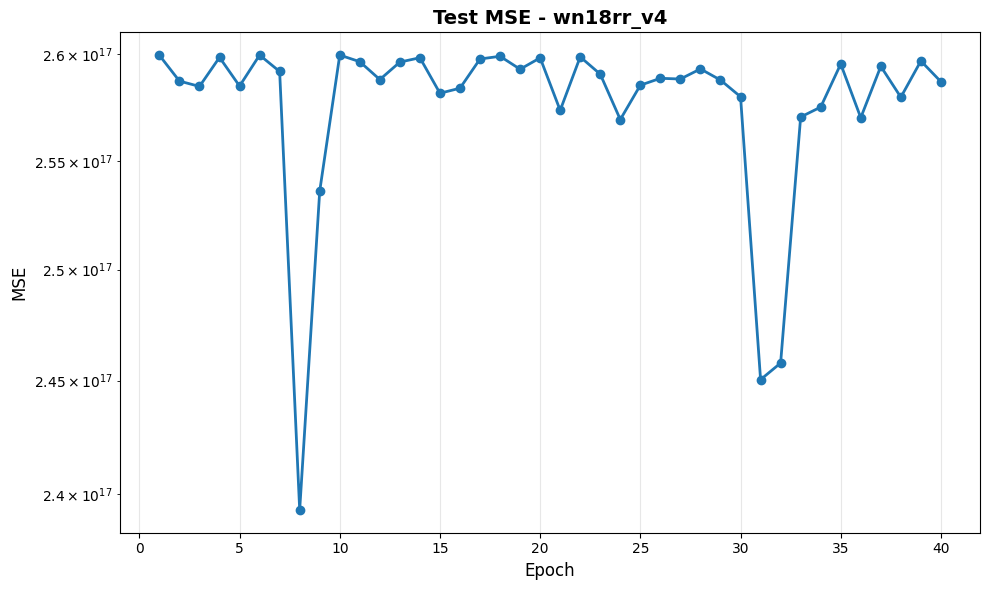

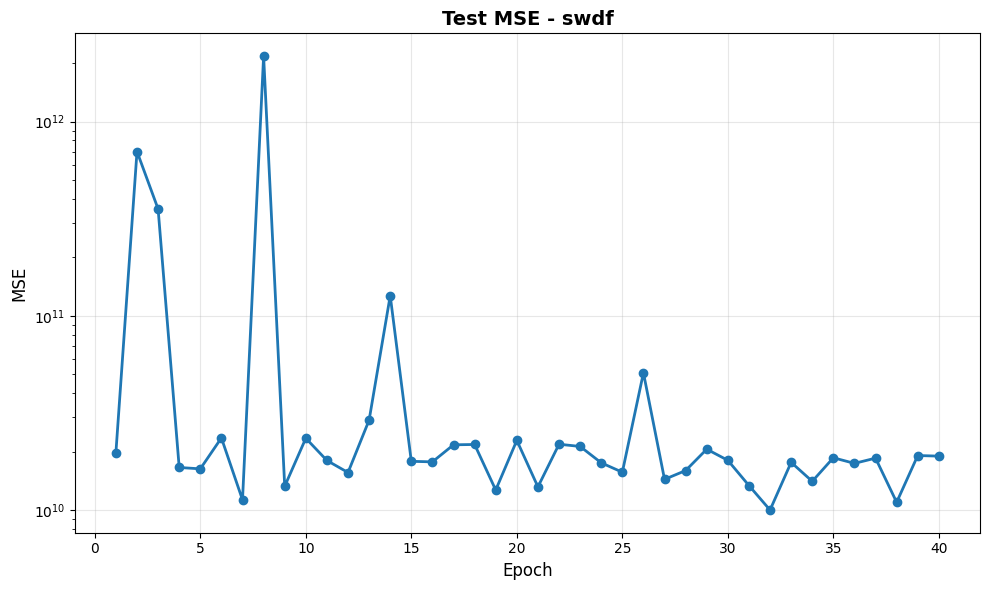

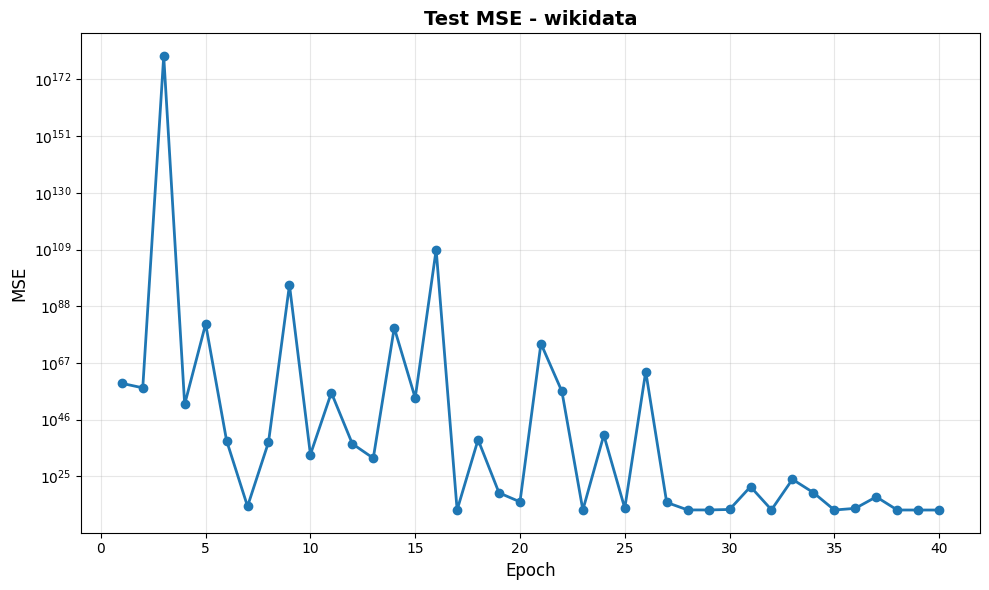

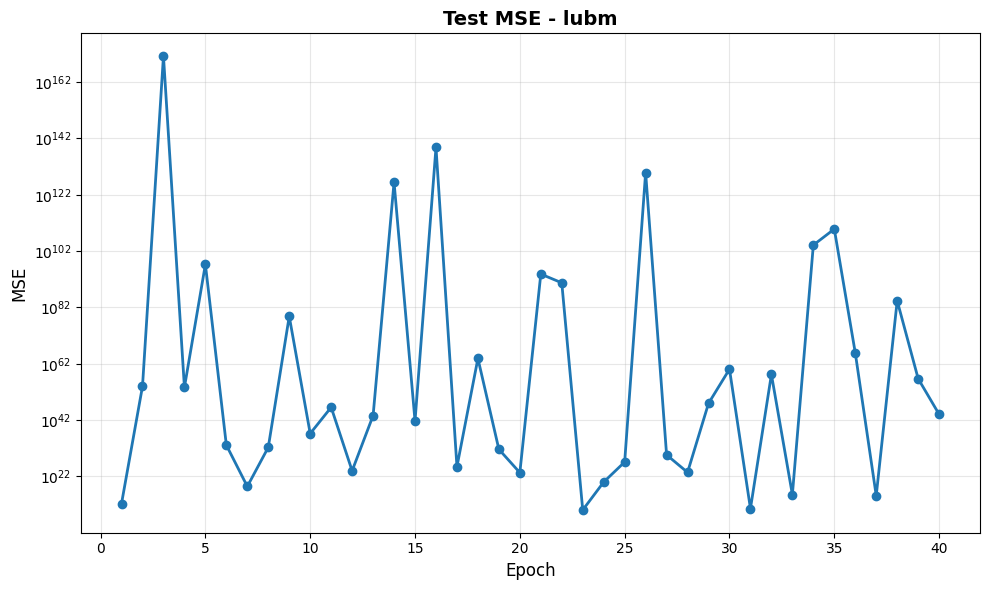

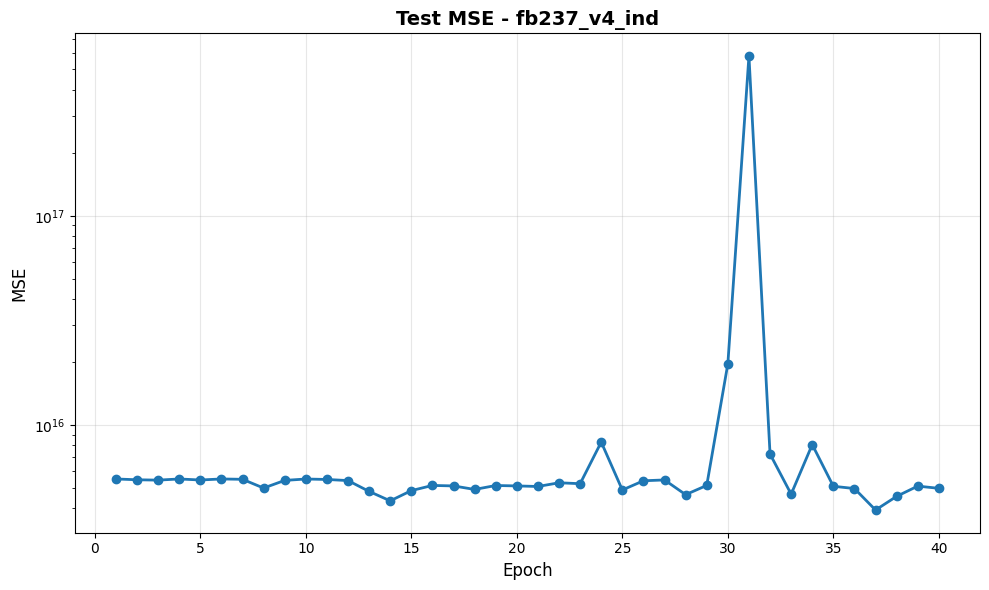

/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/.venv/lib/python3.12/site-packages/matplotlib/ticker.py:2468: RuntimeWarning: overflow encountered in power
  ticklocs = b ** decades


OverflowError: cannot convert float infinity to integer

Error in callback <function _draw_all_if_interactive at 0x11281b880> (for post_execute), with arguments args (),kwargs {}:


OverflowError: cannot convert float infinity to integer

OverflowError: cannot convert float infinity to integer

<Figure size 1000x600 with 1 Axes>

In [11]:
# Define metrics to plot
metrics = ['loss', 'mse', 'mae', 'rmse', 'q_error']

# Metrics that benefit from log scale due to large value ranges
log_scale_metrics = ['mse', 'rmse', 'q_error']

# Create plots for each metric and each dataset combination
for metric in metrics:
    # Test data - one figure per dataset
    for dataset in test_data['dataset_name'].unique():
        fig, ax = plt.subplots(figsize=(10, 6))
        
        dataset_data = test_data[test_data['dataset_name'] == dataset]
        ax.plot(dataset_data['epoch'], dataset_data[metric], marker='o', linewidth=2, markersize=6)
        
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel(metric.upper(), fontsize=12)
        ax.set_title(f'Test {metric.upper()} - {dataset}', fontsize=14, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        if metric in log_scale_metrics:
            ax.set_yscale('log')
        
        plt.tight_layout()
        plt.show()
    
    # Train data - one figure per dataset
    for dataset in train_data['dataset_name'].unique():
        fig, ax = plt.subplots(figsize=(10, 6))
        
        dataset_data = train_data[train_data['dataset_name'] == dataset]
        ax.plot(dataset_data['epoch'], dataset_data[metric], marker='o', linewidth=2, markersize=6, color='C1')
        
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel(metric.upper(), fontsize=12)
        ax.set_title(f'Train {metric.upper()} - {dataset}', fontsize=14, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        if metric in log_scale_metrics:
            ax.set_yscale('log')
        
        plt.tight_layout()
        plt.show()